In [1]:
import scvelo as scv
import scanpy as sc
import scipy.io
import cellrank as cr
import numpy as np

In [2]:

# 1. Basic setup
scv.settings.verbosity = 3  
scv.settings.presenter_view = True  
scv.set_figure_params('scvelo')
# 2. Read the data just exported from R (modified here 👇)
# Use scanpy (sc)'s read_h5ad to load it
adata = sc.read_h5ad("./scRNA/scvelo1.h5ad")
print(adata)

AnnData object with n_obs × n_vars = 4260 × 22177
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'Type', 'ident', 'scDblFinder.class', 'RNA_snn_res.0.4', 'seurat_clusters', 'Celltype', 'oldType', 'Celltype_all', 'RNA_snn_res.0.2', 'sub.cluster', 'pseudotime', 'nCount_spliced', 'nFeature_spliced', 'nCount_unspliced', 'nFeature_unspliced', 'barcode'
    obsm: 'X_pca', 'X_umap'


In [3]:
spliced_matrix = scipy.io.mmread("./spliced_aligned1.mtx").T.tocsr()
unspliced_matrix = scipy.io.mmread("./unspliced_aligned1.mtx").T.tocsr()

# 3. Put the matrices into layers
adata.layers['spliced'] = spliced_matrix
adata.layers['unspliced'] = unspliced_matrix
print(adata)

AnnData object with n_obs × n_vars = 4260 × 22177
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'Type', 'ident', 'scDblFinder.class', 'RNA_snn_res.0.4', 'seurat_clusters', 'Celltype', 'oldType', 'Celltype_all', 'RNA_snn_res.0.2', 'sub.cluster', 'pseudotime', 'nCount_spliced', 'nFeature_spliced', 'nCount_unspliced', 'nFeature_unspliced', 'barcode'
    obsm: 'X_pca', 'X_umap'
    layers: 'spliced', 'unspliced'


In [4]:
adata.obs['Celltype']=adata.obs['sub.cluster']

posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values


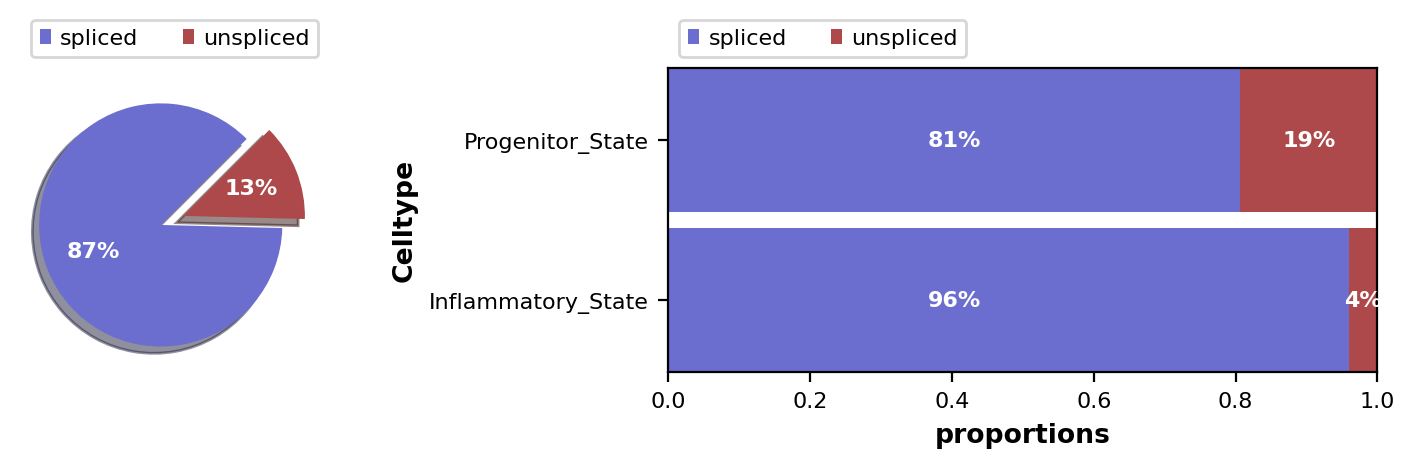

In [5]:
scv.pl.proportions(adata, groupby='Celltype',layers=['spliced', 'unspliced'])


In [6]:
# 1. Filtering: use the scvelo function here because it specifically checks the spliced/unspliced layers
scv.pp.filter_genes(adata, min_shared_counts=20)

# 2. Normalization: use scanpy's standard normalize_total
sc.pp.normalize_total(adata)

# 3. Log-transform: use scanpy's log1p
sc.pp.log1p(adata)

# 4. Find highly variable genes: use scanpy's highly_variable_genes
sc.pp.highly_variable_genes(adata, n_top_genes=2000)

print("Preprocessing done! Computing the neighbor graph and moments (Moments)...")
# 5. Compute moments: back to the scvelo workflow
scv.pp.moments(adata, n_pcs=30, n_neighbors=30)

print("Solving the kinetic model, please wait (this is the slowest step)...")
# 6. Solve the kinetic model
scv.tl.recover_dynamics(adata)

print("Computing velocities...")
# 7. Compute velocities and build the graph
scv.tl.velocity(adata, mode='dynamical')
scv.tl.velocity_graph(adata)


Filtered out 18581 genes that are detected 20 counts (shared).
Preprocessing done! Computing the neighbor graph and moments (Moments)...
Normalized count data: spliced, unspliced.


/tmp/ipykernel_28567/2150871773.py:15: DeprecationWarning: Automatic neighbor calculation is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors first with Scanpy.
  scv.pp.moments(adata, n_pcs=30, n_neighbors=30)
/root/miniconda3/envs/scvelo/lib/python3.9/site-packages/scvelo/preprocessing/moments.py:71: DeprecationWarning: `neighbors` is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors with Scanpy.
  neighbors(
/root/miniconda3/envs/scvelo/lib/python3.9/site-packages/scvelo/preprocessing/neighbors.py:233: DeprecationWarning: Automatic computation of PCA is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute PCA with Scanpy first.
  _set_pca(adata=adata, n_pcs=n_pcs, use_highly_variable=use_highly_variable)


computing neighbors
    finished (0:00:06) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
Solving the kinetic model, please wait (this is the slowest step)...
recovering dynamics (using 1/32 cores)


  0%|          | 0/408 [00:00<?, ?gene/s]

    finished (0:01:41) --> added 
    'fit_pars', fitted parameters for splicing dynamics (adata.var)
Computing velocities...
computing velocities
    finished (0:00:00) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
computing velocity graph (using 1/32 cores)


  0%|          | 0/4260 [00:00<?, ?cells/s]

    finished (0:00:03) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)


In [7]:
custom_colors = {
    'Progenitor_State': '#E7B800',     # 
    'Inflammatory_State': '#FC4E07',
    'Stabilizing_State': '#00AFBB'
    # If there are other cell groups, keep adding them here...
}

# 3. Convert the colors in this dict into a list in categories order and store it in adata.uns 
# Note the naming rule must be: 'your_column_name_colors'
import numpy as np
categories = adata.obs['Celltype'].cat.categories
adata.uns['Celltype_colors'] = [custom_colors[cat] for cat in categories]


Preparing the stream plot...
computing velocity embedding
    finished (0:00:01) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)
saving figure to file ./scRNA/velocity_stream_plot1.pdf


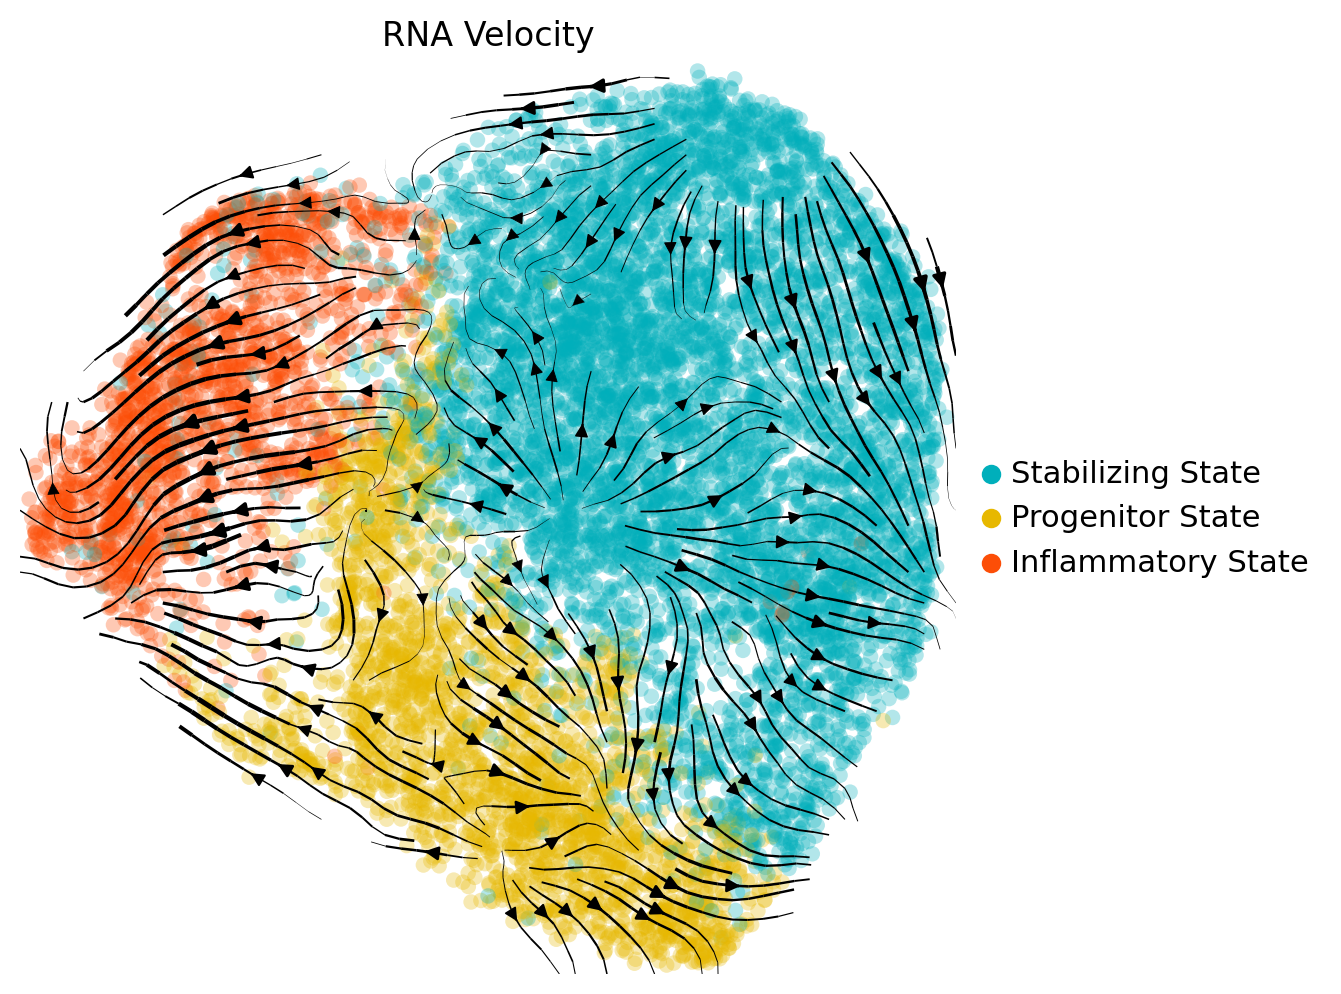

In [37]:

print("Preparing the stream plot...")
# 8. Visualization
scv.pl.velocity_embedding_stream(
    adata, 
    basis='umap', 
    color='Celltype', # Make sure this is your cell type column name in obs
    title='RNA Velocity',figsize=(6, 6),
    legend_loc='right margin',save='./scRNA/velocity_stream_plot1.pdf'
)

/root/miniconda3/envs/scvelo/lib/python3.9/site-packages/scvelo/plotting/scatter.py:656: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  smp = ax.scatter(


saving figure to file ./scRNA/GENE velocity_plot.pdf


/root/miniconda3/envs/scvelo/lib/python3.9/site-packages/matplotlib/backends/backend_pdf.py:1758: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(rgb8, mode='P')


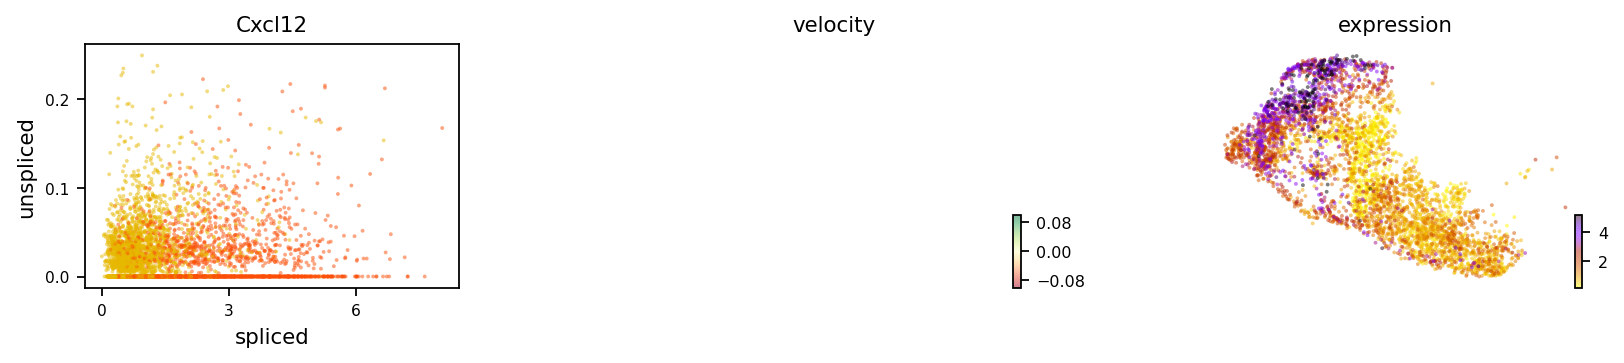

In [9]:
scv.pl.velocity(adata, var_names=['Cxcl12'], color='Celltype',figsize=(8, 4)
                , save='./scRNA/GENE velocity_plot.pdf'
               )

computing terminal states
    identified 2 regions of root cells and 1 region of end points .
    finished (0:00:00) --> added
    'root_cells', root cells of Markov diffusion process (adata.obs)
    'end_points', end points of Markov diffusion process (adata.obs)
running PAGA using priors: ['velocity_pseudotime']
    finished (0:00:00) --> added
    'paga/connectivities', connectivities adjacency (adata.uns)
    'paga/connectivities_tree', connectivities subtree (adata.uns)
    'paga/transitions_confidence', velocity transitions (adata.uns)


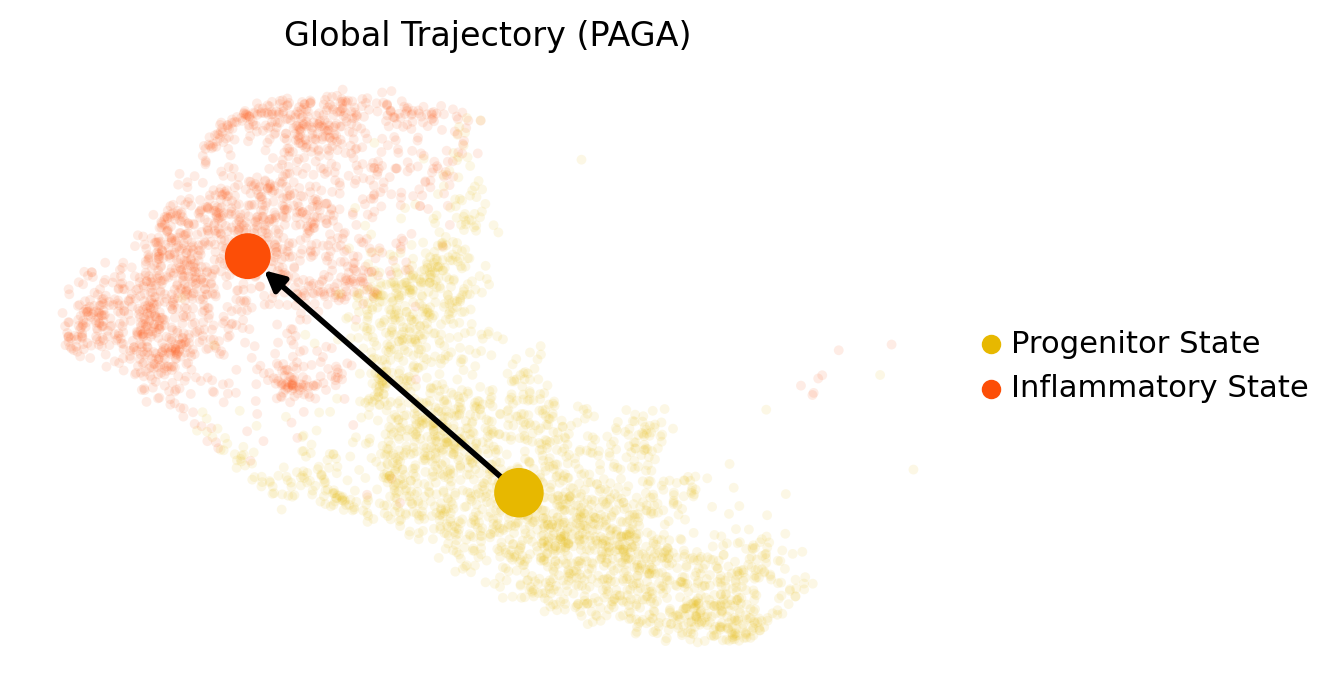

In [20]:
scv.tl.paga(adata, groups='Celltype')

# 2. Overlay the coarse PAGA arrow trajectory on the UMAP embedding
scv.pl.paga(
    adata, 
    basis='umap',          # Still using your UMAP coordinates
    size=50,               # Size of the background cell points
    alpha=.1,              # Make background cells transparent to highlight the main trajectory
    min_edge_width=2,      # Minimum width of the trajectory edges
    node_size_scale=1.5,   # Size of the nodes (cell group centers)
    title='Global Trajectory (PAGA)'
)

In [96]:
adata.obs['velocity_pseudotime1'] = 1 - adata.obs['velocity_pseudotime']


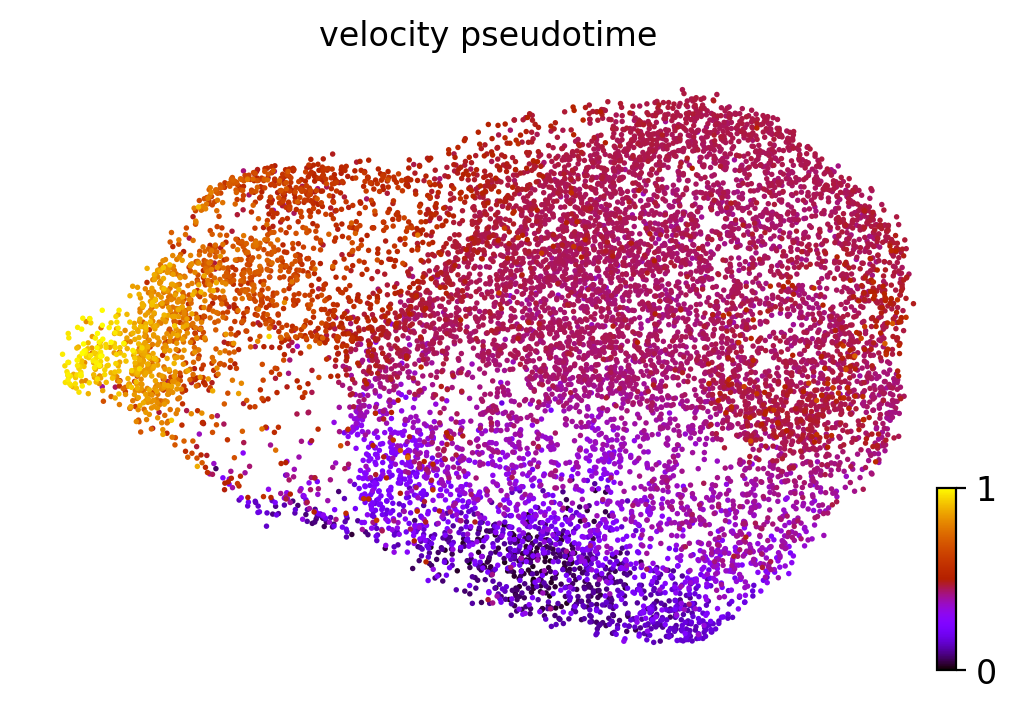

In [42]:
scv.tl.velocity_pseudotime(adata)
scv.pl.scatter(adata, color='velocity_pseudotime', cmap='gnuplot')

In [8]:
vk = cr.kernels.VelocityKernel(adata)
vk.compute_transition_matrix()

/root/miniconda3/envs/scvelo/lib/python3.9/site-packages/cellrank/kernels/_velocity_kernel.py:94: DeprecationWarning: Use of keyword argument `x` is deprecated and replaced by `actual`. Support for `x` will be removed in NumPy 2.2.0.
  np.testing.assert_array_equal(
/root/miniconda3/envs/scvelo/lib/python3.9/site-packages/cellrank/kernels/_velocity_kernel.py:94: DeprecationWarning: Use of keyword argument `y` is deprecated and replaced by `desired`. Support for `y` will be removed in NumPy 2.2.0.
  np.testing.assert_array_equal(


  0%|          | 0/4260 [00:00<?, ?cell/s]

  0%|          | 0/4260 [00:00<?, ?cell/s]

VelocityKernel[n=4260, model='deterministic', similarity='correlation', softmax_scale=np.float64(6.595)]

  0%|          | 0/5 [00:00<?, ?gene/s]

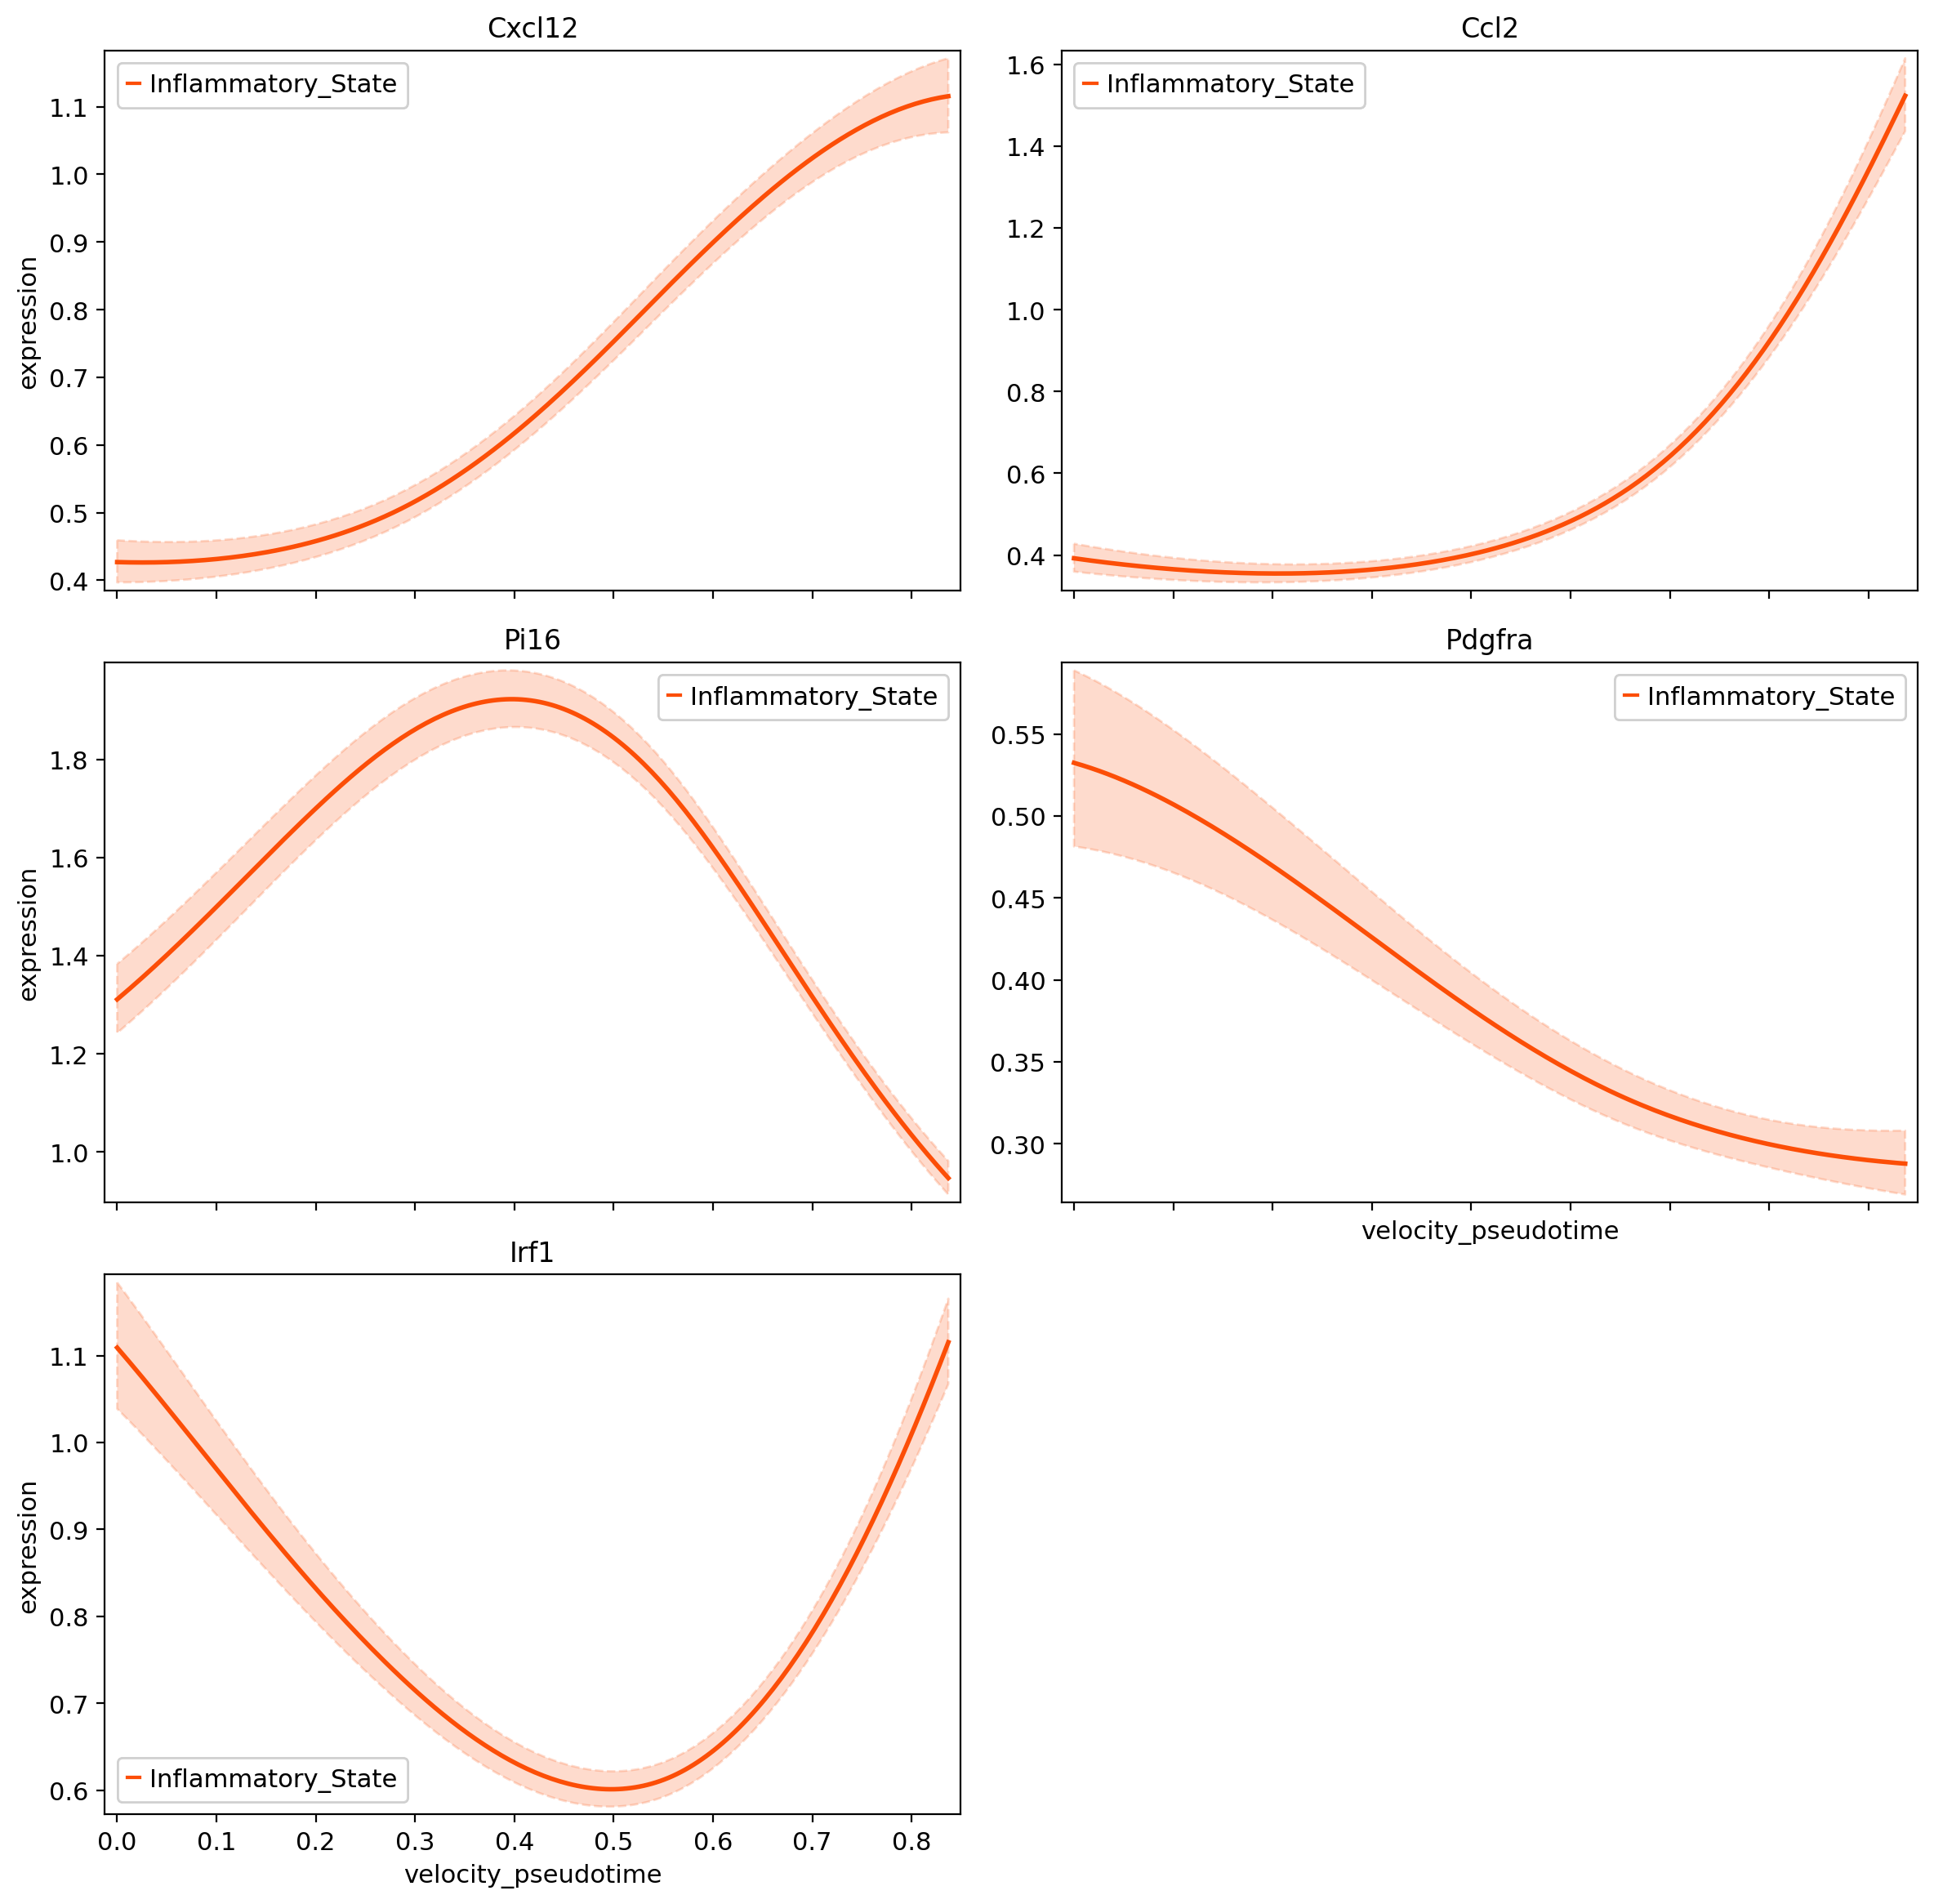

In [25]:
model = cr.models.GAM(adata)
#top_genes = drivers_fmc7.index[:5].tolist()
top_genes=['Cxcl12', 'Ccl2', 'Pi16', 'Pdgfra', 'Ccl7']
# 2. Plot the dynamic trend of gene expression over time
cr.pl.gene_trends(
    adata,
    model=model,
    genes=top_genes ,  #
    lineages=[ 'Inflammatory_State','Progenitor_State'],            # Specify which differentiation lineage to view
    time_key="velocity_pseudotime", # Use developmental time on the X axis (you already computed this when running PAGA)
    same_plot=True,               # True puts several genes in one plot for easy comparison; False plots them separately
    hide_cells=True               # Hide the background cell scatter to make the curves clearer
)